In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
DRIVE_ROOT = "/content/drive/MyDrive/Nexlyra/09-09-26-Ravi"

print("Nexlyra folder exists:", os.path.exists(DRIVE_ROOT))
print("Contents:")
print(os.listdir(DRIVE_ROOT))

Nexlyra folder exists: True
Contents:
['processed_tensors']


In [ ]:
import os
import random
import time
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from torch.utils.data import (Dataset,DataLoader,WeightedRandomSampler)

from sklearn.metrics import (roc_auc_score,precision_score,recall_score,f1_score,confusion_matrix,classification_report)

In [ ]:
BASE_DIR = "/content/drive/MyDrive/Nexlyra/09-09-26-Ravi"

TENSOR_DIR = os.path.join(BASE_DIR,"processed_tensors")
MODEL_DIR = os.path.join(BASE_DIR,"models")
EXPERIMENT_DIR = os.path.join(BASE_DIR,"experiments")
REPORT_DIR = os.path.join( BASE_DIR,"reports")
IMAGE_DIR = os.path.join(BASE_DIR, "image")

os.makedirs(MODEL_DIR,exist_ok=True)
os.makedirs(EXPERIMENT_DIR,exist_ok=True)
os.makedirs(REPORT_DIR,exist_ok=True)
os.makedirs(IMAGE_DIR,exist_ok=True)

print("Directories ready.")

Directories ready.


In [ ]:
### Load Tensors

In [ ]:
# Load final engineered tensors
train_data = torch.load(os.path.join(TENSOR_DIR, "final_train_dual_input.pt"),map_location="cpu")
val_data = torch.load(os.path.join(TENSOR_DIR, "final_val_dual_input.pt"),map_location="cpu")
test_data = torch.load(os.path.join(TENSOR_DIR, "final_test_dual_input.pt"),map_location="cpu")

print("Day 2 tensors loaded successfully.")

Day 2 tensors loaded successfully.


In [ ]:
### Verify the tensors

In [ ]:
print("Train:")
print("  Strain   :", train_data["strain"].shape)
print("  Features :", train_data["features"].shape)
print("  Target   :", train_data["target"].shape)

print("\nValidation:")
print("  Strain   :", val_data["strain"].shape)
print("  Features :", val_data["features"].shape)
print("  Target   :", val_data["target"].shape)

print("\nTest:")
print("  Strain   :", test_data["strain"].shape)
print("  Features :", test_data["features"].shape)
print("  Target   :", test_data["target"].shape)

Train:
  Strain   : torch.Size([747583, 1, 8, 8])
  Features : torch.Size([747583, 5])
  Target   : torch.Size([747583])

Validation:
  Strain   : torch.Size([150000, 1, 8, 8])
  Features : torch.Size([150000, 5])
  Target   : torch.Size([150000])

Test:
  Strain   : torch.Size([150000, 1, 8, 8])
  Features : torch.Size([150000, 5])
  Target   : torch.Size([150000])


In [ ]:
### Reproducibility

In [ ]:
SEED = 42


def set_seed(seed=42):

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if torch.cuda.is_available():

    print("GPU:",torch.cuda.get_device_name(0))
    print("GPU count:",torch.cuda.device_count())

Device: cuda
GPU: Tesla T4
GPU count: 1


In [ ]:
### Dataset Class

In [ ]:
class StrainVisionDataset(Dataset):

    def __init__(self, data):

        self.strain = data["strain"]
        self.features = data["features"]
        self.target = data["target"]

    def __len__(self):

        return len(self.target)

    def __getitem__(self, index):

        return (
            self.strain[index].float(),
            self.features[index].float(),
            self.target[index].float()
        )

In [ ]:
### Create datasets

In [ ]:
train_dataset = StrainVisionDataset(train_data)
val_dataset = StrainVisionDataset(val_data)
test_dataset = StrainVisionDataset(test_data)

print("Train samples:",len(train_dataset))
print("Validation samples:",len(val_dataset))
print("Test samples:",len(test_dataset))

Train samples: 747583
Validation samples: 150000
Test samples: 150000


In [ ]:
### WeightedRandomSampler

In [ ]:
train_targets = (train_data["target"].long())
class_counts = torch.bincount(train_targets,minlength=2)
negative_count = (class_counts[0].item())
positive_count = (class_counts[1].item())

print("Negative samples:",negative_count)
print("Positive samples:",positive_count)

Negative samples: 652417
Positive samples: 95166


In [ ]:
### Create Sampler

In [ ]:
class_weights = torch.tensor([1.0 / negative_count,1.0 / positive_count],dtype=torch.float32)

sample_weights = class_weights[train_targets]

train_sampler = WeightedRandomSampler(weights=sample_weights,
                                     num_samples=len(train_targets),
                                      replacement=True)

In [ ]:
### Data Loader

In [ ]:
BATCH_SIZE = 256

NUM_WORKERS = 2

PIN_MEMORY = torch.cuda.is_available()


train_loader = DataLoader(train_dataset,
                          batch_size=BATCH_SIZE,
                          sampler=train_sampler,
                          num_workers=NUM_WORKERS,
                          pin_memory=PIN_MEMORY)

val_loader = DataLoader(val_dataset,
                        batch_size=BATCH_SIZE,
                        shuffle=False,
                        num_workers=NUM_WORKERS,
                        pin_memory=PIN_MEMORY)

test_loader = DataLoader(test_dataset,
                        batch_size=BATCH_SIZE,
                        shuffle=False,
                        num_workers=NUM_WORKERS,
                        pin_memory=PIN_MEMORY)

In [ ]:
### Final CNN — StrainVisionNet

In [ ]:
class StrainVisionNet(nn.Module):

    def __init__(self,tabular_dim=5):
        super().__init__()


        # SPATIAL CNN BRANCH
        self.spatial_branch = nn.Sequential(
            nn.Conv2d(in_channels=1,out_channels=32,kernel_size=3,padding=1),
            nn.BatchNorm2d(32),
            nn.LeakyReLU(inplace=True),
            nn.Conv2d(in_channels=32,out_channels=64,kernel_size=3,padding=1),
            nn.MaxPool2d(kernel_size=2,stride=2),
            nn.Flatten())

        # TABULAR MLP BRANCH
        self.tabular_branch = nn.Sequential(
            nn.Linear(tabular_dim,64),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.4),
            nn.Linear(64,32),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.4))


        # FUSION
        self.fusion = nn.Sequential(
            nn.Linear(1024 + 32,128),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.4),
            nn.Linear(128,1))

    def forward(self,spatial_x,tabular_x):
        spatial_features = (self.spatial_branch(spatial_x))
        tabular_features = (self.tabular_branch(tabular_x))
        combined_features = torch.cat([spatial_features,tabular_features],dim=1)
        logits = self.fusion(combined_features)
        return logits

In [ ]:
### kaiming intialization

In [ ]:
def initialize_cnn_weights(model):

    for module in model.modules():

        if isinstance(module,nn.Conv2d):
            nn.init.kaiming_uniform_(module.weight,mode="fan_in",nonlinearity="leaky_relu")

            if module.bias is not None:
                nn.init.zeros_(module.bias)

        elif isinstance(module,nn.BatchNorm2d):
            nn.init.ones_(module.weight)
            nn.init.zeros_(module.bias)

In [ ]:
### CNN Shape Varification

In [ ]:
cnn_model = StrainVisionNet()
initialize_cnn_weights(cnn_model)
cnn_model = cnn_model.to(device)

dummy_spatial = torch.randn(512,1,8,8,device=device)
dummy_tabular = torch.randn(512,5,device=device)

cnn_model.eval()

with torch.no_grad():
    dummy_output = cnn_model(dummy_spatial,dummy_tabular)

print("CNN output:",dummy_output.shape)

CNN output: torch.Size([512, 1])


In [ ]:
### ViT experiment architecture (8X8)

In [ ]:
class StrainViT(nn.Module):

    def __init__(self,img_size=8,
                      patch_size=2,
                      in_channels=1,
                      embed_dim=64,
                      num_heads=4,
                      num_layers=2,
                      mlp_ratio=2.0,
                      dropout=0.1,
                      tabular_dim=5):
        super().__init__()

        assert (img_size % patch_size == 0)

        self.img_size = img_size
        self.patch_size = patch_size

        patches_per_side = (img_size // patch_size)
        self.num_patches = (patches_per_side * patches_per_side)
        patch_dim = (in_channels * patch_size * patch_size )


        # PATCH PROJECTION
        self.patch_projection = nn.Linear(patch_dim,embed_dim)


        # POSITIONAL EMBEDDING
        self.position_embedding = nn.Parameter(torch.zeros(1,self.num_patches, embed_dim))


        # TRANSFORMER
        encoder_layer = (nn.TransformerEncoderLayer(d_model=embed_dim,
                                                    nhead=num_heads,
                                                  dim_feedforward=int(embed_dim * mlp_ratio),
                                                   dropout=dropout,
                                                   activation="gelu",
                                                    batch_first=True,
                                                    norm_first=True))

        self.transformer = (nn.TransformerEncoder(encoder_layer,num_layers=num_layers))
        self.norm = nn.LayerNorm(embed_dim)


        # TABULAR MLP
        self.tabular_branch = nn.Sequential( nn.Linear(tabular_dim,64),
                                            nn.ReLU(),
                                            nn.Dropout(0.4),
                                            nn.Linear(64,32),nn.ReLU(),
                                             nn.Dropout(0.4))


        # FUSION
        self.fusion = nn.Sequential(nn.Linear(embed_dim + 32,128),
                                    nn.ReLU(),
                                    nn.Dropout(0.4),nn.Linear(128,1))

    def forward(self,spatial_x,tabular_x):
        B, C, H, W = (spatial_x.shape )
        P = self.patch_size

        # Extract non-overlapping patches
        x = spatial_x.unfold(2,P,P).unfold(3,P,P)

        # [B,C,4,4,P,P]
        x = x.permute(0,2,3,1, 4,5)

        # [B,4,4,C,P,P]
        x = x.contiguous().reshape(B,self.num_patches,-1)

        # [B,16,4]
        x = self.patch_projection(x)

        # [B,16,64]
        x = (x + self.position_embedding)
        x = self.transformer(x)

        # Global token pooling
        x = x.mean(dim=1)
        x = self.norm(x)

        # [B,64]
        tabular_features = ( self.tabular_branch(tabular_x))

        # [B,32]
        combined_features = torch.cat([x,tabular_features],dim=1)
        logits = self.fusion(combined_features)

        return logits

In [ ]:
### Test ViT

In [ ]:
vit_model = StrainViT().to(device)
vit_model.eval()

with torch.no_grad():
    vit_output = vit_model(dummy_spatial,
                           dummy_tabular)

print("ViT output:",vit_output.shape)

ViT output: torch.Size([512, 1])


/tmp/ipykernel_620/2793319405.py:41: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = (nn.TransformerEncoder(encoder_layer,num_layers=num_layers))


In [ ]:
### Parameter Comparison

In [ ]:
def count_trainable_parameters(model):

    return sum(parameter.numel()
               for parameter in model.parameters()
               if parameter.requires_grad)

In [ ]:
cnn_params = count_trainable_parameters(cnn_model)
vit_params = count_trainable_parameters(vit_model)

print(f"CNN parameters: {cnn_params:,}")
print(f"ViT parameters: {vit_params:,}")
print(f"Difference: "
    f"{abs(cnn_params - vit_params):,}")

CNN parameters: 156,769
ViT parameters: 83,425
Difference: 73,344


In [ ]:
### Asymmetry Focal Loss

In [ ]:
class AsymmetricFocalLoss(nn.Module):

    def __init__(self,alpha_neg=2.0,
                     alpha_pos=1.0,
                    gamma_neg=2.0,
                    gamma_pos=1.0):

        super().__init__()

        self.alpha_neg = alpha_neg
        self.alpha_pos = alpha_pos

        self.gamma_neg = gamma_neg
        self.gamma_pos = gamma_pos

    def forward(self,logits,targets):

        targets = targets.float().view_as(logits)
        probabilities = torch.sigmoid(logits)
        p_pos = probabilities
        p_neg = 1.0 - probabilities

        positive_loss = (targets* torch.log(torch.clamp( p_pos,min=1e-8)))
        negative_loss = ((1.0 - targets) * torch.log(torch.clamp(p_neg,min=1e-8)))

        positive_focal = ( 1.0 - p_pos).pow(self.gamma_pos)
        negative_focal = (1.0 - p_neg).pow(self.gamma_neg)

        loss = (self.alpha_pos* positive_focal* positive_loss +
                self.alpha_neg* negative_focal* negative_loss)

        return -loss.mean()

In [ ]:
criterion = AsymmetricFocalLoss(alpha_neg=2.0,alpha_pos=1.0,gamma_neg=2.0,gamma_pos=1.0)

In [ ]:
### MixUp

In [ ]:
def mixup_dual_input(strain_batch,
                     features_batch,
                     target_batch,
                     alpha=0.2,
                     p=0.5):

    if torch.rand(1,device=strain_batch.device).item() > p:

        return (strain_batch,
                features_batch,
                target_batch,
                target_batch,
                torch.tensor(1.0,device=strain_batch.device))

    beta = torch.distributions.Beta(alpha,alpha)
    lam = beta.sample().to(strain_batch.device)
    permutation = torch.randperm(strain_batch.size(0),device=strain_batch.device)
    mixed_strain = (lam * strain_batch + (1.0 - lam) * strain_batch[permutation])
    mixed_features = ( lam * features_batch + (1.0 - lam) * features_batch[permutation])
    target_a = target_batch
    target_b = target_batch[permutation]

    return (mixed_strain,
            mixed_features,
            target_a,
            target_b,
            lam)

In [ ]:
### AMP Compatibility

In [ ]:
AMP_ENABLED = torch.cuda.is_available()
scaler = torch.amp.GradScaler("cuda",enabled=AMP_ENABLED)
print("AMP enabled:",AMP_ENABLED)

AMP enabled: True


In [ ]:
### Training Function

In [ ]:
def train_one_epoch(model,
                   loader,
                   optimizer,
                  criterion,
                  scaler,
                  device,
                  mixup_alpha=0.2,
                  mixup_probability=0.5,
                  max_grad_norm=1.0):

    model.train()
    running_loss = 0.0
    total_samples = 0

    for (spatial_x,
        tabular_x,
        targets) in loader:

        spatial_x = spatial_x.to(device,non_blocking=True)
        tabular_x = tabular_x.to(device,non_blocking=True)
        targets = targets.to(device,non_blocking=True)

        (spatial_x,tabular_x,
         target_a,target_b,
         lam) = mixup_dual_input(spatial_x,tabular_x,targets,alpha=mixup_alpha,p=mixup_probability)
        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(device_type="cuda",enabled=AMP_ENABLED):
               logits = model(spatial_x,tabular_x)
               target_a = (target_a.float().view_as(logits))
               target_b = (target_b.float().view_as(logits))
               loss_a = criterion(logits,target_a)
               loss_b = criterion(logits,target_b)
               loss = (lam * loss_a + (1.0 - lam) * loss_b)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(model.parameters(),max_norm=max_grad_norm)

        scaler.step(optimizer)
        scaler.update()

        batch_size = (spatial_x.size(0))
        running_loss += (loss.item() * batch_size)
        total_samples += (batch_size)

    return (running_loss/ total_samples)

In [ ]:
### Validation Function

In [ ]:
def validate(model,loader,criterion,device,threshold=0.5):

    model.eval()
    running_loss = 0.0
    total_samples = 0
    all_targets = []
    all_probabilities = []

    with torch.no_grad():

        for (spatial_x,tabular_x,targets) in loader:
            spatial_x = spatial_x.to(device,non_blocking=True)
            tabular_x = tabular_x.to(device,non_blocking=True)
            targets = targets.to(device,non_blocking=True)

            with torch.amp.autocast(device_type="cuda",enabled=AMP_ENABLED):

                logits = model(spatial_x,tabular_x)
                target_view = (targets.float().view_as(logits))
                loss = criterion(logits,target_view)

            probabilities = torch.sigmoid(logits).squeeze(1)
            batch_size = (spatial_x.size(0))
            running_loss += (loss.item()* batch_size)
            total_samples += (batch_size)

            all_targets.append(targets.detach().cpu())
            all_probabilities.append(probabilities.detach().cpu())

    epoch_loss = (running_loss / total_samples)

    all_targets = torch.cat(all_targets).numpy()
    all_probabilities = torch.cat(all_probabilities).numpy()
    predictions = (all_probabilities >= threshold).astype(np.int64)

    auroc = roc_auc_score(all_targets,all_probabilities)
    precision = precision_score(all_targets,predictions,zero_division=0)
    recall = recall_score(all_targets,predictions,zero_division=0)
    f1 = f1_score(all_targets,predictions,zero_division=0)

    return {
        "loss": epoch_loss,
        "auroc": auroc,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "targets": all_targets,
        "probabilities": all_probabilities,
        "predictions": predictions
    }

In [ ]:
### DataParallel Helper

In [ ]:
def unwrap_model(model):
    if isinstance(model,nn.DataParallel):
        return model.module

    return model

In [ ]:
### Multi-GPU Wrapper

In [ ]:
def prepare_model_for_device(model,device):

    model = model.to(device)

    if (torch.cuda.is_available() and torch.cuda.device_count() > 1):
        print(
            f"Using DataParallel "
            f"with {torch.cuda.device_count()} GPUs.")

        model = nn.DataParallel(model)

    else:
        print("Single-device training.")
    return model

In [ ]:
### Archirecture Experiment

In [ ]:
def run_architecture_experiment(model,model_name,train_loader,val_loader,
                                criterion,device, epochs=10,learning_rate=2e-4,
                               weight_decay=1e-4,patience=5):

    model = prepare_model_for_device(model, device)

    optimizer = torch.optim.AdamW(model.parameters(),
                                  lr=learning_rate,
                                weight_decay=weight_decay)

    scheduler = (torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=epochs))
    experiment_scaler = torch.amp.GradScaler("cuda",enabled=AMP_ENABLED)

    history = {
        "epoch": [],
        "train_loss": [],
        "val_loss": [],
        "val_auroc": [],
        "val_precision": [],
        "val_recall": [],
        "val_f1": [],
        "learning_rate": []
    }

    best_auroc = -float("inf")
    best_epoch = 0
    patience_counter = 0
    best_state = None

    start_time = time.time()

    for epoch in range(epochs):

        train_loss = train_one_epoch(
            model=model,
            loader=train_loader,
            optimizer=optimizer,
            criterion=criterion,
            scaler=experiment_scaler,
            device=device)

        val_results = validate(
            model=model,
            loader=val_loader,
            criterion=criterion,
            device=device,
            threshold=0.5)

        scheduler.step()

        val_loss = val_results["loss"]
        val_auroc = val_results["auroc"]
        val_precision = val_results["precision"]
        val_recall = val_results["recall"]
        val_f1 = val_results["f1"]

        current_lr = (optimizer.param_groups[0]["lr"])

        history["epoch"].append(epoch + 1)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_auroc"].append(val_auroc)
        history["val_precision"].append(val_precision)
        history["val_recall"].append(val_recall)
        history["val_f1"].append(val_f1)
        history["learning_rate"].append(current_lr)

        print(
            f"{model_name} | "
            f"Epoch "
            f"{epoch + 1:02d}/{epochs} | "
            f"Train Loss: {train_loss:.5f} | "
            f"Val Loss: {val_loss:.5f} | "
            f"AUROC: {val_auroc:.5f} | "
            f"Precision: {val_precision:.5f} | "
            f"Recall: {val_recall:.5f} | "
            f"F1: {val_f1:.5f}"
        )

        if val_auroc > best_auroc:
            best_auroc = val_auroc
            best_epoch = epoch + 1
            patience_counter = 0

            base_model = unwrap_model(model)

            best_state = {
                key: value.detach().cpu().clone()
                for key, value
                in base_model.state_dict().items()
            }

            print(
                "  ✓ New best model."
            )

        else:

            patience_counter += 1

            print(
                f"  No improvement "
                f"({patience_counter}/{patience})")

            if ( patience_counter >= patience):

                print("  Early stopping.")

                break

    training_time = ( time.time() - start_time)

    history_df = pd.DataFrame(history)
    history_path = os.path.join(EXPERIMENT_DIR,
                          f"{model_name.lower()}_history.csv")
    history_df.to_csv(history_path,index=False)

    return {
        "model_name": model_name,
        "best_auroc": best_auroc,
        "best_epoch": best_epoch,
        "training_time": training_time,
        "best_state": best_state,
        "history": history
    }

In [ ]:
### Task 43–45 — Run CNN experiment

In [ ]:
cnn_experiment = StrainVisionNet()

initialize_cnn_weights(cnn_experiment)

cnn_results = run_architecture_experiment(
    model=cnn_experiment,
    model_name="CNN",
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    device=device,
    epochs=10,
    learning_rate=2e-4,
    weight_decay=1e-4,
    patience=5
)

Single-device training.
CNN | Epoch 01/10 | Train Loss: 0.04580 | Val Loss: 0.00187 | AUROC: 1.00000 | Precision: 1.00000 | Recall: 0.99990 | F1: 0.99995
  ✓ New best model.
CNN | Epoch 02/10 | Train Loss: nan | Val Loss: 0.00096 | AUROC: 1.00000 | Precision: 1.00000 | Recall: 0.99990 | F1: 0.99995
  No improvement (1/5)
CNN | Epoch 03/10 | Train Loss: nan | Val Loss: 0.00472 | AUROC: 1.00000 | Precision: 1.00000 | Recall: 0.99990 | F1: 0.99995
  No improvement (2/5)
CNN | Epoch 04/10 | Train Loss: nan | Val Loss: 0.00434 | AUROC: 1.00000 | Precision: 1.00000 | Recall: 0.99990 | F1: 0.99995
  No improvement (3/5)
CNN | Epoch 05/10 | Train Loss: nan | Val Loss: 0.00487 | AUROC: 1.00000 | Precision: 1.00000 | Recall: 0.99990 | F1: 0.99995
  No improvement (4/5)
CNN | Epoch 06/10 | Train Loss: nan | Val Loss: 0.00451 | AUROC: 1.00000 | Precision: 1.00000 | Recall: 0.99990 | F1: 0.99995
  No improvement (5/5)
  Early stopping.


In [ ]:
### Run ViT experiment

In [ ]:
vit_experiment = StrainViT()

vit_results = run_architecture_experiment(
    model=vit_experiment,
    model_name="ViT",
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    device=device,
    epochs=10,
    learning_rate=2e-4,
    weight_decay=1e-4,
    patience=5
)

Single-device training.


/tmp/ipykernel_620/2793319405.py:41: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = (nn.TransformerEncoder(encoder_layer,num_layers=num_layers))


ViT | Epoch 01/10 | Train Loss: 0.05868 | Val Loss: 0.00123 | AUROC: 1.00000 | Precision: 1.00000 | Recall: 1.00000 | F1: 1.00000
  ✓ New best model.
ViT | Epoch 02/10 | Train Loss: 0.04349 | Val Loss: 0.00393 | AUROC: 1.00000 | Precision: 1.00000 | Recall: 1.00000 | F1: 1.00000
  No improvement (1/5)
ViT | Epoch 03/10 | Train Loss: 0.03941 | Val Loss: 0.00055 | AUROC: 1.00000 | Precision: 1.00000 | Recall: 1.00000 | F1: 1.00000
  No improvement (2/5)
ViT | Epoch 04/10 | Train Loss: 0.03868 | Val Loss: 0.00090 | AUROC: 1.00000 | Precision: 1.00000 | Recall: 1.00000 | F1: 1.00000
  No improvement (3/5)
ViT | Epoch 05/10 | Train Loss: 0.03676 | Val Loss: 0.00160 | AUROC: 1.00000 | Precision: 1.00000 | Recall: 1.00000 | F1: 1.00000
  No improvement (4/5)
ViT | Epoch 06/10 | Train Loss: 0.03625 | Val Loss: 0.00114 | AUROC: 1.00000 | Precision: 1.00000 | Recall: 1.00000 | F1: 1.00000
  No improvement (5/5)
  Early stopping.


In [ ]:
### Task 44 — Parameter comparison

In [ ]:
comparison = pd.DataFrame({
    "Architecture": ["CNN","ViT"],
    "Parameters": [cnn_params,vit_params],
    "Best_Validation_AUROC": [cnn_results["best_auroc"],vit_results["best_auroc"]],
    "Best_Epoch": [cnn_results["best_epoch"],vit_results["best_epoch"]],
    "Training_Time_Minutes": [cnn_results["training_time"] / 60,vit_results["training_time"] / 60]
})

print(comparison)

  Architecture  Parameters  Best_Validation_AUROC  Best_Epoch  \
0          CNN      156769                    1.0           1   
1          ViT       83425                    1.0           1   

   Training_Time_Minutes  
0               3.651422  
1               5.412950  


In [ ]:
### Save

In [ ]:
comparison_path = os.path.join(EXPERIMENT_DIR,"architecture_comparison.csv")
comparison.to_csv(comparison_path,index=False)

In [ ]:
### Task 45 — Determine convergence

In [ ]:
cnn_auroc = (cnn_results["best_auroc"])
vit_auroc = (vit_results["best_auroc"])
cnn_epoch = (cnn_results["best_epoch"])
vit_epoch = ( vit_results["best_epoch"])
cnn_time = (cnn_results["training_time"])
vit_time = ( vit_results["training_time"])

print("\nARCHITECTURE CONVERGENCE")
print("========================")

if cnn_epoch < vit_epoch:

    print("CNN reached its best validation "
          "AUROC in fewer epochs.")

elif vit_epoch < cnn_epoch:

    print("ViT reached its best validation "
          "AUROC in fewer epochs.")

else:

    print("Both architectures reached their "
          "best validation AUROC at the same epoch.")

print(f"\nCNN AUROC: {cnn_auroc:.5f}")
print(f"ViT AUROC: {vit_auroc:.5f}")
print(f"CNN time: {cnn_time / 60:.2f} minutes")
print(f"ViT time: {vit_time / 60:.2f} minutes")


ARCHITECTURE CONVERGENCE
Both architectures reached their best validation AUROC at the same epoch.

CNN AUROC: 1.00000
ViT AUROC: 1.00000
CNN time: 3.65 minutes
ViT time: 5.41 minutes


In [ ]:
### Plot CNN vs ViT convergence

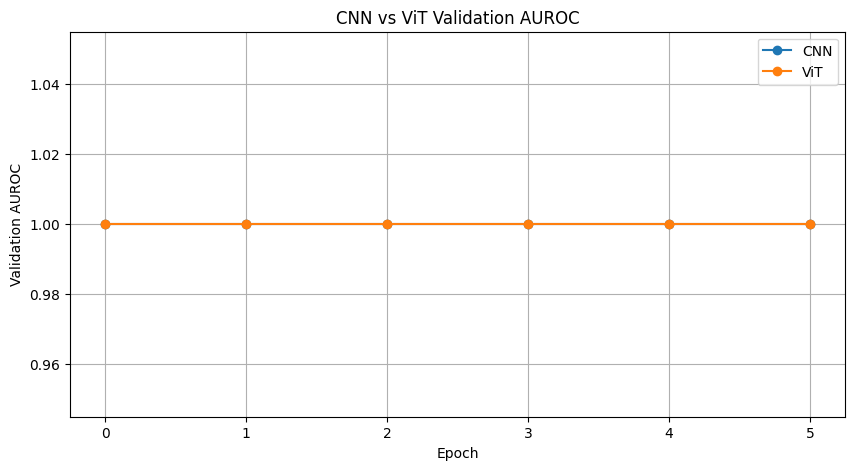

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(cnn_results["history"]["val_auroc"],marker="o",label="CNN")
plt.plot(vit_results["history"]["val_auroc"],marker="o",label="ViT")
plt.xlabel("Epoch")
plt.ylabel("Validation AUROC")
plt.title("CNN vs ViT Validation AUROC")
plt.legend()
plt.grid(True)
plt.savefig(f"{IMAGE_DIR}/CNN_VS_ViT.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
### Task 46 — Architecture selection

In [ ]:
AUROC_TOLERANCE = 0.005

In [ ]:
if (cnn_auroc >= vit_auroc or ( abs(cnn_auroc - vit_auroc) <= AUROC_TOLERANCE and cnn_params <= vit_params)):

    FINAL_ARCHITECTURE = "CNN"
    final_base_model = (StrainVisionNet())
    final_base_model.load_state_dict(cnn_results["best_state"])

else:
    FINAL_ARCHITECTURE = "ViT"
    final_base_model = (StrainViT())
    final_base_model.load_state_dict(vit_results["best_state"])

print("Selected architecture:",FINAL_ARCHITECTURE)

Selected architecture: CNN


In [ ]:
### Task 47 — DataParallel

In [ ]:
final_model = prepare_model_for_device(final_base_model,device)

Single-device training.


In [ ]:
### Task 49 — Device verification

In [ ]:
def verify_devices(model,loader,device):

    model_device = next(model.parameters()).device
    spatial_x, tabular_x, target = next(iter(loader))
    spatial_x = spatial_x.to(device,non_blocking=True)
    tabular_x = tabular_x.to(device,non_blocking=True)
    target = target.to(device,non_blocking=True)
    model.eval()

    with torch.no_grad():
        output = model(spatial_x,tabular_x)

    print("Model device  :",model_device)
    print("Spatial device:",spatial_x.device)
    print("Feature device:",tabular_x.device )
    print("Target device :",target.device)
    print("Output device :",output.device)
    print("Output shape  :",output.shape)

    assert (spatial_x.device== tabular_x.device)
    assert (tabular_x.device == target.device)
    assert (output.device == spatial_x.device)

    print("\nPASS: All tensors are on "
         "compatible devices.")

In [ ]:
verify_devices(final_model,train_loader,device)

In [ ]:
### Final optimizer

In [ ]:
FINAL_EPOCHS = 20
FINAL_LR = 2e-4
FINAL_WEIGHT_DECAY = 1e-4
FINAL_PATIENCE = 5

final_optimizer = torch.optim.AdamW(final_model.parameters(),lr=FINAL_LR,weight_decay=FINAL_WEIGHT_DECAY)

In [ ]:
### Final scheduler

In [ ]:
final_scheduler = (torch.optim.lr_scheduler.CosineAnnealingLR(final_optimizer,T_max=FINAL_EPOCHS))

In [ ]:
### Final AMP scaler

In [ ]:
final_scaler = torch.amp.GradScaler("cuda",enabled=AMP_ENABLED)

In [ ]:
### Final checkpoint paths

In [ ]:
FINAL_BEST_MODEL_PATH = os.path.join( MODEL_DIR,"StrainVisionNet_best.pt")
FINAL_MODEL_PATH = os.path.join(MODEL_DIR,"StrainVisionNet_final.pt")
FINAL_HISTORY_PATH = os.path.join(EXPERIMENT_DIR,"final_training_history.csv")
FINAL_METRICS_PATH = os.path.join(REPORT_DIR,"day3_test_metrics.csv")

In [ ]:
### Task 50 — Final optimized training

In [ ]:
final_history = {
    "epoch": [],
    "train_loss": [],
    "val_loss": [],
    "val_auroc": [],
    "val_precision": [],
    "val_recall": [],
    "val_f1": [],
    "learning_rate": []
}

best_final_auroc = -float("inf")
best_final_epoch = 0
epochs_without_improvement = 0


for epoch in range(FINAL_EPOCHS):

    # TRAIN

    train_loss = train_one_epoch(
        model=final_model,
        loader=train_loader,
        optimizer=final_optimizer,
        criterion=criterion,
        scaler=final_scaler,
        device=device,
        mixup_alpha=0.2,
        mixup_probability=0.5,
        max_grad_norm=1.0
    )

    # VALIDATION

    val_results = validate(
        model=final_model,
        loader=val_loader,
        criterion=criterion,
        device=device,
        threshold=0.5
    )

    val_loss = val_results["loss"]
    val_auroc = val_results["auroc"]
    val_precision = (val_results["precision"])
    val_recall = (val_results["recall"])
    val_f1 = (val_results["f1"])

    # Scheduler

    final_scheduler.step()
    current_lr = (final_optimizer.param_groups[0]["lr"])

    # History

    final_history["epoch"].append(epoch + 1)
    final_history["train_loss"].append(train_loss)
    final_history["val_loss"].append(val_loss)
    final_history["val_auroc"].append(val_auroc)
    final_history["val_precision"].append(val_precision)
    final_history["val_recall"].append(val_recall)
    final_history["val_f1"].append(val_f1)
    final_history["learning_rate"].append(current_lr)


    # Logging

    print(
        f"Epoch [{epoch + 1:02d}/{FINAL_EPOCHS}] | "
        f"Train Loss: {train_loss:.5f} | "
        f"Val Loss: {val_loss:.5f} | "
        f"AUROC: {val_auroc:.5f} | "
        f"Precision: {val_precision:.5f} | "
        f"Recall: {val_recall:.5f} | "
        f"F1: {val_f1:.5f} | "
        f"LR: {current_lr:.7f}"
    )


    # Best validation AUROC

    if val_auroc > best_final_auroc:

        best_final_auroc = val_auroc
        best_final_epoch = (epoch + 1)
        epochs_without_improvement = 0
        base_model = unwrap_model(final_model)

        torch.save(
            {
                "model_state_dict":
                    base_model.state_dict(),

                "optimizer_state_dict":
                    final_optimizer.state_dict(),

                "scheduler_state_dict":
                    final_scheduler.state_dict(),

                "epoch":
                    epoch + 1,

                "val_auroc":
                    val_auroc,

                "val_precision":
                    val_precision,

                "val_recall":
                    val_recall,

                "val_f1":
                    val_f1,

                "architecture":
                    FINAL_ARCHITECTURE,

                "input_spatial_shape":
                    [1, 8, 8],

                "input_tabular_features":
                    5
            },
            FINAL_BEST_MODEL_PATH
        )

        print("  ✓ Best checkpoint saved.")

    else:

        epochs_without_improvement += 1

        print(
            f"  No improvement "
            f"{epochs_without_improvement}/"
            f"{FINAL_PATIENCE}")

        if (epochs_without_improvement >= FINAL_PATIENCE):

            print( "\nEarly stopping triggered.")

            break

Epoch [01/20] | Train Loss: nan | Val Loss: 0.00106 | AUROC: 1.00000 | Precision: 1.00000 | Recall: 0.99990 | F1: 0.99995 | LR: 0.0001988
  ✓ Best checkpoint saved.
Epoch [02/20] | Train Loss: nan | Val Loss: 0.00701 | AUROC: 1.00000 | Precision: 1.00000 | Recall: 1.00000 | F1: 1.00000 | LR: 0.0001951
  No improvement 1/5
Epoch [03/20] | Train Loss: nan | Val Loss: 0.00784 | AUROC: 1.00000 | Precision: 1.00000 | Recall: 1.00000 | F1: 1.00000 | LR: 0.0001891
  No improvement 2/5
Epoch [04/20] | Train Loss: nan | Val Loss: 0.00634 | AUROC: 1.00000 | Precision: 1.00000 | Recall: 1.00000 | F1: 1.00000 | LR: 0.0001809
  No improvement 3/5
Epoch [05/20] | Train Loss: nan | Val Loss: 0.00703 | AUROC: 1.00000 | Precision: 1.00000 | Recall: 1.00000 | F1: 1.00000 | LR: 0.0001707
  No improvement 4/5
Epoch [06/20] | Train Loss: nan | Val Loss: 0.00692 | AUROC: 1.00000 | Precision: 1.00000 | Recall: 1.00000 | F1: 1.00000 | LR: 0.0001588
  No improvement 5/5

Early stopping triggered.


In [ ]:
### Load the best validation model

In [ ]:
checkpoint = torch.load(FINAL_BEST_MODEL_PATH,map_location=device,weights_only=False)
base_final_model = unwrap_model(final_model)
base_final_model.load_state_dict(checkpoint["model_state_dict"])
final_model.eval()

print("Best model loaded.")
print("Best epoch:",checkpoint["epoch"])
print("Best validation AUROC:",checkpoint["val_auroc"])

Best model loaded.
Best epoch: 1
Best validation AUROC: 1.0


In [ ]:
### Final validation evaluation

In [ ]:
final_val_results = validate(
    model=final_model,
    loader=val_loader,
    criterion=criterion,
    device=device,
    threshold=0.5
)

print("\nFINAL VALIDATION")
print("================")

print(f"Loss      : "
    f"{final_val_results['loss']:.5f}")

print(f"AUROC     : "
    f"{final_val_results['auroc']:.5f}")

print(
    f"Precision : "
    f"{final_val_results['precision']:.5f}")

print(
    f"Recall    : "
    f"{final_val_results['recall']:.5f}")

print(
    f"F1        : "
    f"{final_val_results['f1']:.5f}")


FINAL VALIDATION
Loss      : 0.00106
AUROC     : 1.00000
Precision : 1.00000
Recall    : 0.99990
F1        : 0.99995


In [ ]:
### Final untouched TEST evaluation

In [ ]:
final_test_results = validate(
    model=final_model,
    loader=test_loader,
    criterion=criterion,
    device=device,
    threshold=0.5
)

print("\nFINAL TEST RESULTS")
print("==================")

print(f"Test Loss      : "
    f"{final_test_results['loss']:.5f}")

print(f"Test AUROC     : "
    f"{final_test_results['auroc']:.5f}")

print(f"Test Precision : "
    f"{final_test_results['precision']:.5f}")

print(f"Test Recall    : "
    f"{final_test_results['recall']:.5f}")

print(f"Test F1        : "
    f"{final_test_results['f1']:.5f}")


FINAL TEST RESULTS
Test Loss      : 0.00106
Test AUROC     : 1.00000
Test Precision : 1.00000
Test Recall    : 1.00000
Test F1        : 1.00000


In [ ]:
### Final confusion matrix

In [ ]:
final_cm = confusion_matrix(final_test_results["targets"],final_test_results["predictions"])

tn, fp, fn, tp = (final_cm.ravel())

print("\nCONFUSION MATRIX")
print("================")

print(final_cm)

print("\nTrue Negatives :",tn)
print("False Positives:",fp)
print("False Negatives:",fn)
print("True Positives :",tp)


CONFUSION MATRIX
[[139804      0]
 [     0  10196]]

True Negatives : 139804
False Positives: 0
False Negatives: 0
True Positives : 10196


In [ ]:
### Classification report

In [ ]:
print(classification_report(final_test_results["targets"],final_test_results["predictions"],
                            target_names=["Legitimate","Failure / Spoof"],zero_division=0))

                 precision    recall  f1-score   support

     Legitimate       1.00      1.00      1.00    139804
Failure / Spoof       1.00      1.00      1.00     10196

       accuracy                           1.00    150000
      macro avg       1.00      1.00      1.00    150000
   weighted avg       1.00      1.00      1.00    150000



In [ ]:
### Save final model

In [ ]:
base_final_model = unwrap_model(final_model)

torch.save(
    {
        "model_state_dict":base_final_model.state_dict(),
        "architecture":FINAL_ARCHITECTURE,
        "input_spatial_shape":[1, 8, 8],
        "input_tabular_features": 5,
        "output_type": "raw_logit",
        "cnn_parameters":cnn_params,
        "vit_parameters":vit_params,
        "best_validation_auroc":best_final_auroc,
        "best_validation_epoch":best_final_epoch,
        "test_auroc":final_test_results["auroc"],
        "test_precision":final_test_results["precision"],
        "test_recall":final_test_results["recall"],
        "test_f1":final_test_results["f1"],
        "training_configuration":
            {
                "batch_size":BATCH_SIZE,
                "learning_rate":FINAL_LR,
                "weight_decay":FINAL_WEIGHT_DECAY,
                "epochs":FINAL_EPOCHS,
                "early_stopping_patience":FINAL_PATIENCE,
                "optimizer":"AdamW",
                "scheduler":"CosineAnnealingLR",
                "loss":"AsymmetricFocalLoss",
                "mixup_alpha": 0.2,
                "mixup_probability":0.5,
                "gradient_clip_norm":1.0,
                "amp":AMP_ENABLED
            }
    },
    FINAL_MODEL_PATH
)

print("Final model saved:")
print(FINAL_MODEL_PATH)

Final model saved:
/content/drive/MyDrive/Nexlyra/09-09-26-Ravi/models/StrainVisionNet_final.pt


In [ ]:
### Save final metrics

In [ ]:
metrics_df = pd.DataFrame([
    {
        "Architecture":FINAL_ARCHITECTURE,
        "Best_Validation_AUROC":best_final_auroc,
        "Best_Epoch":best_final_epoch,
        "Test_Loss":final_test_results["loss"],
        "Test_AUROC":final_test_results["auroc"],
        "Test_Precision":final_test_results["precision"],
        "Test_Recall":final_test_results["recall"],
        "Test_F1":final_test_results["f1"],
        "True_Negatives":tn,
        "False_Positives":fp,
        "False_Negatives": fn,
        "True_Positives":tp
    }
])

metrics_df.to_csv(FINAL_METRICS_PATH,index=False)
print("Final metrics saved:")
print(FINAL_METRICS_PATH)

Final metrics saved:
/content/drive/MyDrive/Nexlyra/09-09-26-Ravi/reports/day3_test_metrics.csv


In [ ]:
### Training loss curve

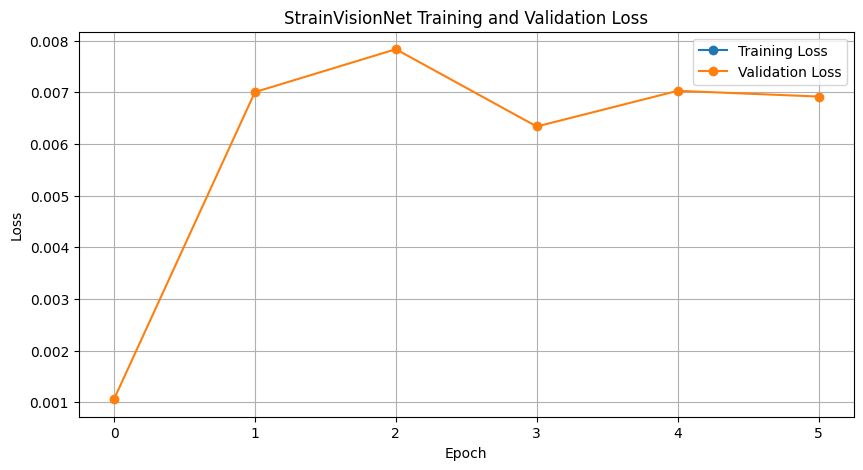

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(final_history["train_loss"],marker="o",label="Training Loss")
plt.plot(final_history["val_loss"],marker="o",label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("StrainVisionNet Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.savefig(f"{IMAGE_DIR}/Training_loss.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
### Validation AUROC curve

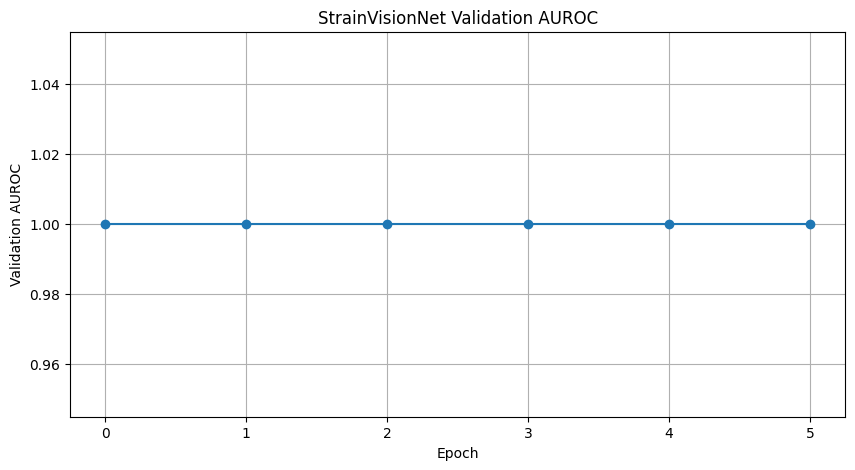

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(final_history["val_auroc"],marker="o")
plt.xlabel("Epoch")
plt.ylabel("Validation AUROC")
plt.title("StrainVisionNet Validation AUROC")
plt.grid(True)
plt.savefig(f"{IMAGE_DIR}/Validation_AUROC.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
### Validation F1 curve

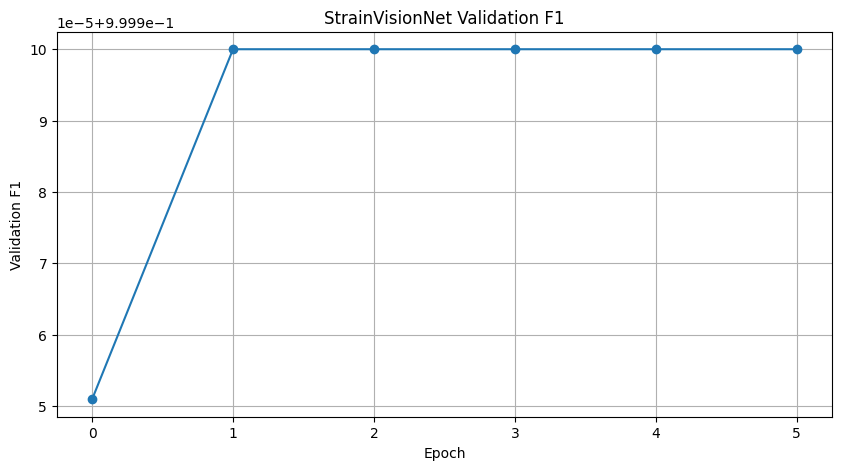

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(final_history["val_f1"],marker="o")
plt.xlabel("Epoch")
plt.ylabel("Validation F1")
plt.title("StrainVisionNet Validation F1")
plt.grid(True)
plt.savefig(f"{IMAGE_DIR}/Validation_F1.png", dpi=300, bbox_inches="tight")
plt.show()